<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Sequence%20Classification%20using%20RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 360ms/step - accuracy: 0.5031 - loss: 0.6937 - val_accuracy: 0.5078 - val_loss: 0.6925
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 358ms/step - accuracy: 0.5297 - loss: 0.6887 - val_accuracy: 0.5294 - val_loss: 0.6885
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 83s 368ms/step - accuracy: 0.6409 - loss: 0.6319 - val_accuracy: 0.7210 - val_loss: 0.5887

MODEL EVALUATION
Test Loss: 0.5944
Test Accuracy: 71.19 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.70      0.73      0.72     12500
    Positive       0.72      0.69      0.71     12500

    accuracy                           0.71     25000
   macro avg       0.71      0.71      0.71     25000
weighted avg       0.71      0.71      0.71     25000



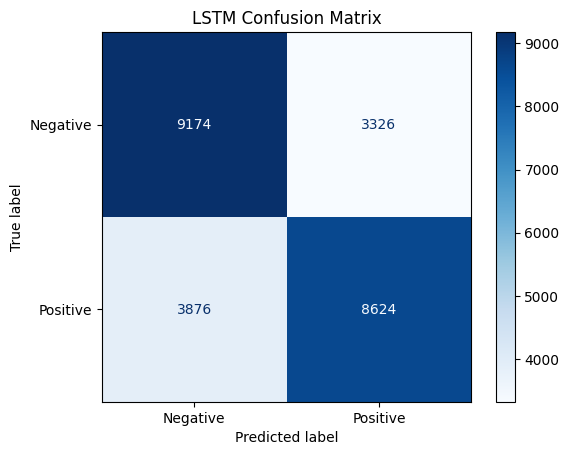

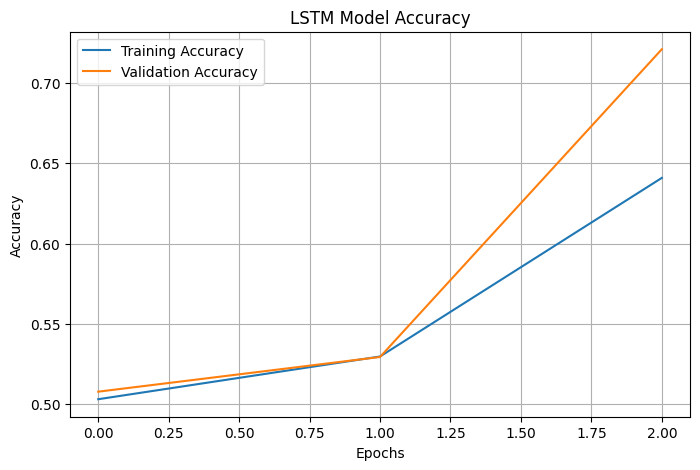

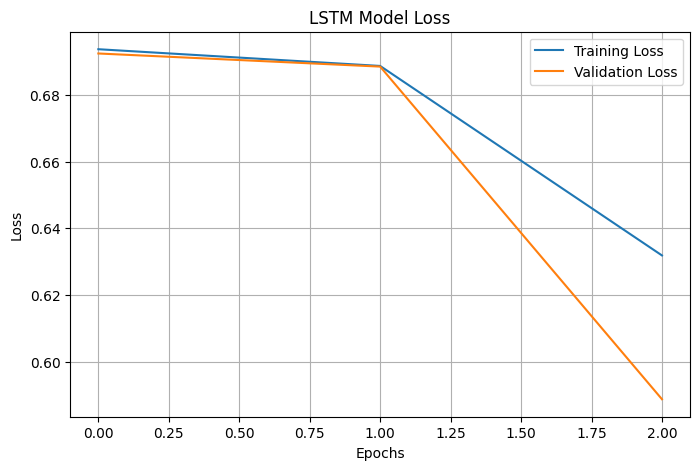

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

CUSTOM REVIEW PREDICTION
Review: This movie was amazing and wonderful I really enjoyed it
Positive Probability: 0.7719
Predicted Sentiment: Positive

Sequence Classification Completed Successfully!


In [10]:

# Sequence Classification using RNN/LSTM (Keras/TensorFlow)

!pip install -q tensorflow

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load IMDB movie review dataset
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Padding sequences
X_train = pad_sequences(
    X_train, maxlen=max_length, padding='post', truncating='post'
)

X_test = pad_sequences(
    X_test, maxlen=max_length, padding='post', truncating='post'
)

# Build LSTM model
model = Sequential([
    Embedding(vocab_size, 64, input_length=max_length),
    LSTM(64, dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

# Train model
history = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("\nMODEL EVALUATION")
print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Generate predictions
predictions = model.predict(X_test, verbose=0)
predicted_labels = (predictions > 0.5).astype(int).flatten()

# Classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, predicted_labels,
    target_names=['Negative', 'Positive']
))

# Confusion matrix
cm = confusion_matrix(y_test, predicted_labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
).plot(cmap='Blues')

plt.title("LSTM Confusion Matrix")
plt.show()

# Training accuracy visualization
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("LSTM Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Training loss visualization
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("LSTM Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Test custom review
word_index = imdb.get_word_index()

def encode_review(text):
    words = text.lower().split()
    sequence = [
        word_index.get(word, 2) + 3
        for word in words
    ]
    sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )
    return sequence

custom_review = "This movie was amazing and wonderful I really enjoyed it"

custom_sequence = encode_review(custom_review)
prediction = model.predict(custom_sequence, verbose=0)[0][0]

print("\nCUSTOM REVIEW PREDICTION")
print("Review:", custom_review)
print("Positive Probability:", round(float(prediction), 4))
print("Predicted Sentiment:", "Positive" if prediction >= 0.5 else "Negative")

print("\nSequence Classification Completed Successfully!")
